# Signature verification — simplified notebook
Rewritten so each step is short and does one thing.

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

## 1. Setup

In [ ]:
!unzip -q -n "/content/drive/MyDrive/Colab Notebooks/Signature_Recognition/data/signature-rec-colab.zip" -d /content/data

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from tqdm import tqdm

DATA_ROOT = Path("/content/data")
OUT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Signature_Recognition/outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(DATA_ROOT / "manifest.csv", dtype={"writer_id": str, "person_id": str})
print(len(manifest), "images,", manifest.person_id.nunique(), "people")

42374 images, 1412 people


## 2. Data card: genuine / forged images per person, summarized per source

In [ ]:
per_person = manifest.groupby(["source", "person_id", "label"]).size().unstack("label", fill_value=0)
per_source = per_person.groupby("source").agg(["min", "median", "max"])
per_source["people"] = per_person.groupby("source").size()
per_source

label           forged            genuine            people
                   min median max     min median max       
source                                                     
b01_jpg_5g5f         5    5.0   5       5    5.0   5     48
b02_tif_24g30f      15   30.0  30       6   24.0  24    252
b03_png_24g24f      24   24.0  24      24   24.0  24     55
b04_png_15g15f       5   15.0  60       5   15.0  50     11
b05_jpg_11g11f      10   11.0  20      10   11.0  20    686
b06_png_30g12f      12   12.0  12      30   30.0  30     30
b07_png_5g5f         5    5.0   5       5    5.0   5     70
b08_png_12g12f       8   12.0  20      12   12.0  24     64
b10_png_5g5f         5    5.0   5       5    5.0   5     30
b11_jpeg_38g36f     36   36.0  36      37   38.0  40     37
b12_png_30g24f      24   24.0  24      30   30.0  30     30
b13_png_5g10f       10   10.0  15       5    5.0  10     69
b14_jpg_40g40f      20   40.0  40      20   40.0  40     30

## 3. Split people into train / val / test
- The unit is a **person**, never an image.
- Inside each source: 70% train, 15% val, 15% test.
- People made of several writer IDs (merged aliases) always go to train.
- Computed once, saved, and loaded from disk afterwards.

In [ ]:
SPLIT_FILE = OUT_DIR / "split.csv"

def make_split(manifest, seed=42):
    rng = np.random.default_rng(seed)
    source_of_person = manifest.groupby("person_id")["source"].first()
    ids_per_person = manifest.groupby("person_id")["writer_id"].nunique()
    merged_people = set(ids_per_person[ids_per_person > 1].index)

    split_of = {person: "train" for person in merged_people}
    for source, people in source_of_person.groupby(source_of_person):
        people = [p for p in people.index if p not in merged_people]
        rng.shuffle(people)
        n = round(0.15 * len(people))
        for p in people[:n]:
            split_of[p] = "val"
        for p in people[n:2 * n]:
            split_of[p] = "test"
        for p in people[2 * n:]:
            split_of[p] = "train"
    return pd.Series(split_of, name="split").rename_axis("person_id")

if not SPLIT_FILE.exists():
    make_split(manifest).to_csv(SPLIT_FILE)
split_of = pd.read_csv(SPLIT_FILE, dtype={"person_id": str}).set_index("person_id")["split"]
manifest["split"] = manifest["person_id"].map(split_of)

assert manifest["split"].notna().all()
assert manifest.groupby("person_id")["split"].nunique().max() == 1   # nobody in two splits
manifest.groupby(["source", "split"])["person_id"].nunique().unstack()

split,test,train,val
source,,,
b01_jpg_5g5f,7,34,7
b02_tif_24g30f,38,176,38
b03_png_24g24f,8,39,8
b04_png_15g15f,1,9,1
b05_jpg_11g11f,103,480,103
b06_png_30g12f,4,22,4
b07_png_5g5f,10,50,10
b08_png_12g12f,10,44,10
b10_png_5g5f,4,22,4


In [ ]:
train_df = manifest[manifest.split == "train"]
val_df = manifest[manifest.split == "val"]
# test_df is not created on purpose: it is used once, at the very end.

## 4. Metric: Equal Error Rate
`labels`: 1 = genuine, 0 = forgery. `scores`: higher = more likely genuine.

In [ ]:
def compute_eer(labels, scores):
    far, tpr, _ = roc_curve(labels, scores)
    frr = 1 - tpr
    i = np.argmin(np.abs(far - frr))
    return (far[i] + frr[i]) / 2

def frr_at_far(labels, scores, target_far=0.01):
    far, tpr, _ = roc_curve(labels, scores)
    return 1 - tpr[far <= target_far].max()

In [ ]:
# Sanity checks for the metric
labels = np.array([1] * 500 + [0] * 500)
print("random   (expect ~0.50):", compute_eer(labels, np.random.rand(1000)))
print("oracle   (expect  0.00):", compute_eer(labels, labels))
print("inverted (expect  1.00):", compute_eer(labels, 1 - labels))

random   (expect ~0.50): 0.51
oracle   (expect  0.00): 0.0
inverted (expect  1.00): 1.0


## 5. Verification trials
For each person: the first `k` genuine signatures are the references; their average is the **template**.
Every query is scored by its cosine similarity to the template. Three kinds of query:
- `genuine`: the person's other genuine signatures (should score high)
- `skilled`: forgeries of this person (should score low)
- `random`: genuine signatures of other people (should score low)

The result is one table, one row per query. Every metric below is computed from that table.
`features` is a dict: image path -> feature vector. This works for any feature extractor.

In [ ]:
def cosine_similarity(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

def build_trials(df, features, k, n_random=20, seed=0):
    rng = np.random.default_rng(seed)
    all_genuine = df[df.label == "genuine"]
    rows = []
    for person_id, person in df.groupby("person_id"):
        genuine = person[person.label == "genuine"].path.tolist()
        forged = person[person.label == "forged"].path.tolist()
        if len(genuine) <= k:
            continue   # not enough genuine signatures left to query with
        references, genuine_queries = genuine[:k], genuine[k:]
        others = all_genuine[all_genuine.person_id != person_id].path
        random_queries = others.sample(n_random, random_state=rng.integers(1_000_000)).tolist()

        template = np.mean([features[p] for p in references], axis=0)
        source = person.source.iloc[0]
        for kind, paths in [("genuine", genuine_queries), ("skilled", forged), ("random", random_queries)]:
            for path in paths:
                rows.append((person_id, source, kind, cosine_similarity(template, features[path])))
    return pd.DataFrame(rows, columns=["person_id", "source", "kind", "score"])

In [ ]:
def eer_against(trials, forgery_kind):
    t = trials[trials.kind.isin(["genuine", forgery_kind])]
    return compute_eer(t.kind == "genuine", t.score)

def report(trials):
    for kind in ["skilled", "random"]:
        t = trials[trials.kind.isin(["genuine", kind])]
        is_genuine = t.kind == "genuine"
        print(f"{kind:8s} EER: {compute_eer(is_genuine, t.score):.3f}   "
              f"FRR at FAR=1%: {frr_at_far(is_genuine, t.score):.3f}")

def report_per_source(trials):
    rows = []
    for source, t in trials.groupby("source"):
        rows.append({"source": source,
                     "people": t.person_id.nunique(),
                     "skilled_eer": eer_against(t, "skilled"),
                     "random_eer": eer_against(t, "random")})
    return pd.DataFrame(rows).round(3)

def plot_roc(trials, forgery_kind, title=""):
    t = trials[trials.kind.isin(["genuine", forgery_kind])]
    far, tpr, _ = roc_curve(t.kind == "genuine", t.score)
    plt.plot(far, tpr, label=forgery_kind)
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Acceptance Rate")
    plt.ylabel("True Acceptance Rate (1 - FRR)")
    plt.title(title)
    plt.legend()

## 6. Baseline: HOG + LBP features (no learning)

In [ ]:
import cv2
from skimage.feature import hog, local_binary_pattern

def hog_lbp_features(path):
    image = cv2.imread(str(DATA_ROOT / path), cv2.IMREAD_GRAYSCALE)
    image = cv2.resize(image, (256, 256))
    hog_part = hog(image, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
    lbp = local_binary_pattern(image, P=8, R=1, method="uniform")
    lbp_part = np.histogram(lbp, bins=10, range=(0, 10), density=True)[0]
    return np.concatenate([hog_part, lbp_part])

baseline_features = {path: hog_lbp_features(path) for path in tqdm(val_df.path)}

100%|██████████| 6215/6215 [02:30<00:00, 41.36it/s]


In [ ]:
for k in [1, 5]:
    print(f"--- Baseline, k={k} ---")
    report(build_trials(val_df, baseline_features, k))

--- Baseline, k=1 ---
skilled  EER: 0.420   FRR at FAR=1%: 0.933
random   EER: 0.211   FRR at FAR=1%: 0.630
--- Baseline, k=5 ---
skilled  EER: 0.356   FRR at FAR=1%: 0.898
random   EER: 0.175   FRR at FAR=1%: 0.499


In [ ]:
baseline_trials = build_trials(val_df, baseline_features, k=5)
report_per_source(baseline_trials)

,source,people,skilled_eer,random_eer
0,b02_tif_24g30f,38,0.306,0.099
1,b03_png_24g24f,8,0.090,0.048
2,b05_jpg_11g11f,103,0.536,0.285
3,b06_png_30g12f,4,0.122,0.000
4,b08_png_12g12f,10,0.292,0.049
5,b11_jpeg_38g36f,6,0.246,0.112
6,b12_png_30g24f,4,0.168,0.023
7,b14_jpg_40g40f,4,0.246,0.027


## 7. Deep embedder: ResNet-18 trained to recognize training **people**
- Trained on **genuine signatures only**: a forgery must not be taught as "this is person X".
- After training, the classifier is thrown away and the backbone output (128 numbers) is the embedding.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class SignatureImages(Dataset):
    def __init__(self, paths, labels):
        self.paths = list(paths)
        self.labels = list(labels)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = Image.open(DATA_ROOT / self.paths[i]).convert("RGB")
        return transform(image), self.labels[i]

In [ ]:
def make_model(num_people, embedding_dim=128):
    backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    backbone.fc = nn.Linear(backbone.fc.in_features, embedding_dim)
    classifier = nn.Linear(embedding_dim, num_people)
    return nn.Sequential(backbone, classifier)   # model[0] = backbone -> embeddings

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = nn.functional.cross_entropy(logits, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        seen += len(labels)
    return total_loss / seen, correct / seen

def training_loader(df, batch_size):
    genuine = df[df.label == "genuine"]
    people = sorted(genuine.person_id.unique())
    class_of = {person: i for i, person in enumerate(people)}
    dataset = SignatureImages(genuine.path, genuine.person_id.map(class_of))
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=2), len(people)

In [ ]:
# Sanity check: the model must be able to memorize 20 people perfectly
tiny_people = train_df.person_id.drop_duplicates().head(20)
tiny_loader, n_tiny = training_loader(train_df[train_df.person_id.isin(tiny_people)], batch_size=16)
tiny_model = make_model(n_tiny).to(device)
optimizer = torch.optim.Adam(tiny_model.parameters(), lr=1e-3)
for epoch in range(1, 31):
    loss, accuracy = train_one_epoch(tiny_model, tiny_loader, optimizer)
    if epoch % 5 == 0:
        print(f"epoch {epoch:2d}  loss {loss:.3f}  accuracy {accuracy:.0%}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


epoch  5  loss 0.134  accuracy 99%
epoch 10  loss 0.051  accuracy 100%
epoch 15  loss 0.339  accuracy 91%
epoch 20  loss 0.101  accuracy 99%
epoch 25  loss 0.114  accuracy 95%
epoch 30  loss 0.011  accuracy 100%


In [ ]:
loader, num_people = training_loader(train_df, batch_size=64)
model = make_model(num_people).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

for epoch in range(1, 6):
    loss, accuracy = train_one_epoch(model, tqdm(loader, desc=f"epoch {epoch}"), optimizer)
    print(f"epoch {epoch}  loss {loss:.3f}  accuracy {accuracy:.1%}")

torch.save(model.state_dict(), OUT_DIR / "resnet18_people.pt")

epoch 1: 100%|██████████| 230/230 [01:18<00:00,  2.93it/s]


epoch 1  loss 5.461  accuracy 21.1%


epoch 2: 100%|██████████| 230/230 [01:13<00:00,  3.13it/s]


epoch 2  loss 3.312  accuracy 54.5%


epoch 3: 100%|██████████| 230/230 [01:14<00:00,  3.10it/s]


epoch 3  loss 2.040  accuracy 73.3%


epoch 4: 100%|██████████| 230/230 [01:13<00:00,  3.12it/s]


epoch 4  loss 0.899  accuracy 93.8%


epoch 5: 100%|██████████| 230/230 [01:13<00:00,  3.13it/s]

epoch 5  loss 0.260  accuracy 99.7%


## 8. Evaluate the deep embedder with the exact same trial code as the baseline

In [ ]:
@torch.no_grad()
def embed(model, paths):
    backbone = model[0].eval()
    loader = DataLoader(SignatureImages(paths, [0] * len(paths)), batch_size=64, num_workers=2)
    vectors = [backbone(images.to(device)).cpu().numpy() for images, _ in tqdm(loader)]
    return dict(zip(paths, np.concatenate(vectors)))

deep_features = embed(model, list(val_df.path))
for k in [1, 5]:
    print(f"--- Deep model, k={k} ---")
    report(build_trials(val_df, deep_features, k))

100%|██████████| 98/98 [00:31<00:00,  3.16it/s]


--- Deep model, k=1 ---
skilled  EER: 0.218   FRR at FAR=1%: 0.818
random   EER: 0.018   FRR at FAR=1%: 0.053
--- Deep model, k=5 ---
skilled  EER: 0.137   FRR at FAR=1%: 0.681
random   EER: 0.009   FRR at FAR=1%: 0.008


In [ ]:
deep_trials = build_trials(val_df, deep_features, k=5)
report_per_source(deep_trials)

,source,people,skilled_eer,random_eer
0,b02_tif_24g30f,38,0.091,0.011
1,b03_png_24g24f,8,0.028,0.000
2,b05_jpg_11g11f,103,0.169,0.009
3,b06_png_30g12f,4,0.204,0.011
4,b08_png_12g12f,10,0.105,0.000
5,b11_jpeg_38g36f,6,0.193,0.016
6,b12_png_30g24f,4,0.071,0.000
7,b14_jpg_40g40f,4,0.143,0.000


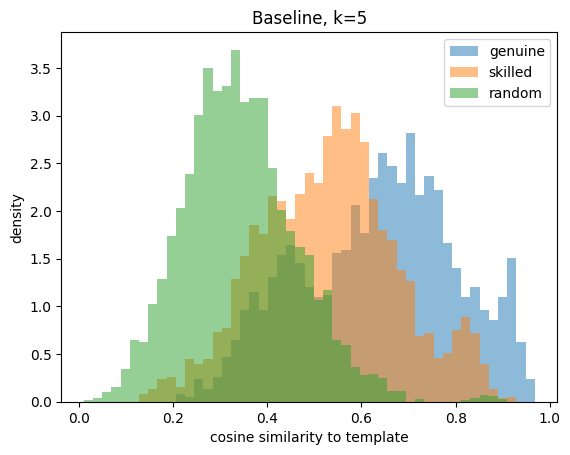

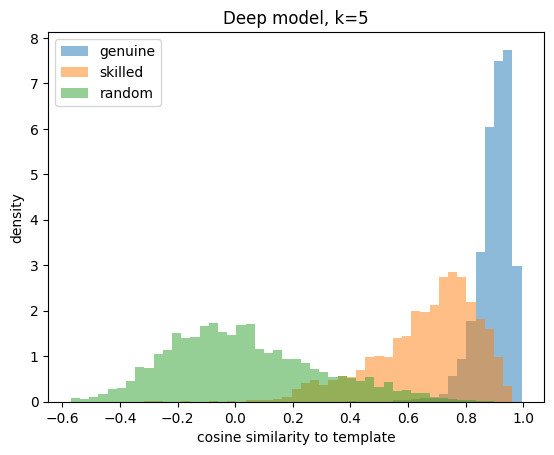

In [ ]:
def plot_score_distributions(trials, title):
    bins = np.linspace(trials.score.min(), trials.score.max(), 50)
    for kind in ["genuine", "skilled", "random"]:
        scores = trials[trials.kind == kind].score
        plt.hist(scores, bins=bins, alpha=0.5, density=True, label=kind)
    plt.xlabel("cosine similarity to template")
    plt.ylabel("density")
    plt.title(title)
    plt.legend()
    plt.show()

plot_score_distributions(baseline_trials, "Baseline, k=5")
plot_score_distributions(deep_trials, "Deep model, k=5")

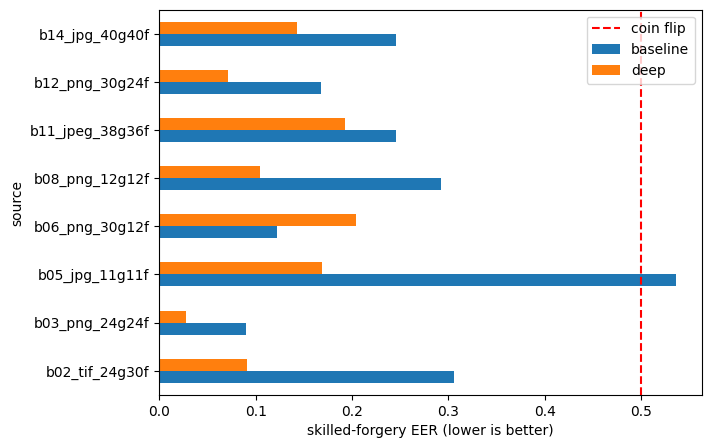

In [ ]:
comparison = pd.DataFrame({
    "baseline": report_per_source(baseline_trials).set_index("source")["skilled_eer"],
    "deep": report_per_source(deep_trials).set_index("source")["skilled_eer"],
})
comparison.plot.barh(figsize=(7, 5))
plt.axvline(0.5, color="red", linestyle="--", label="coin flip")
plt.xlabel("skilled-forgery EER (lower is better)")
plt.legend()
plt.show()

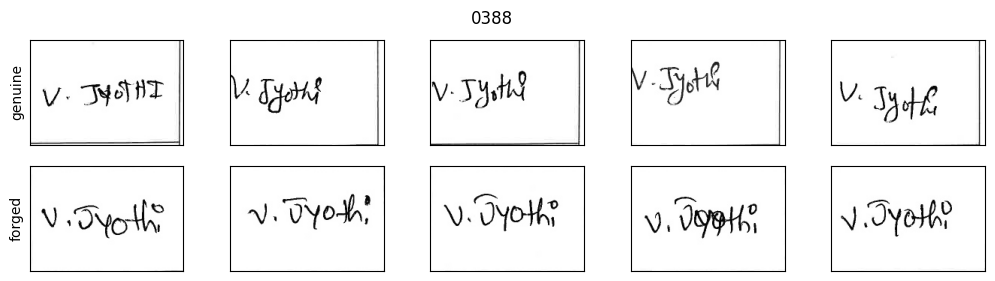

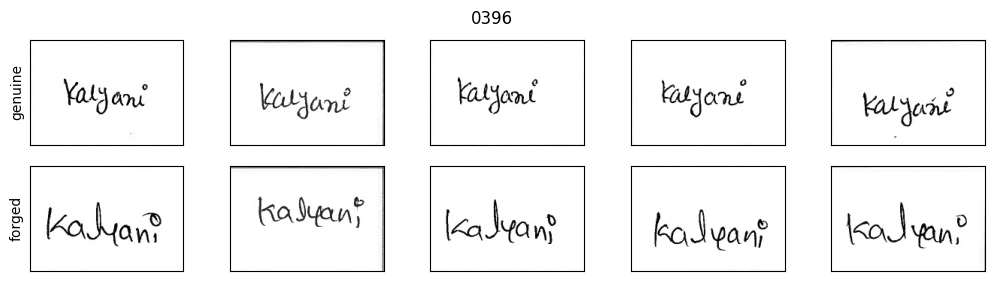

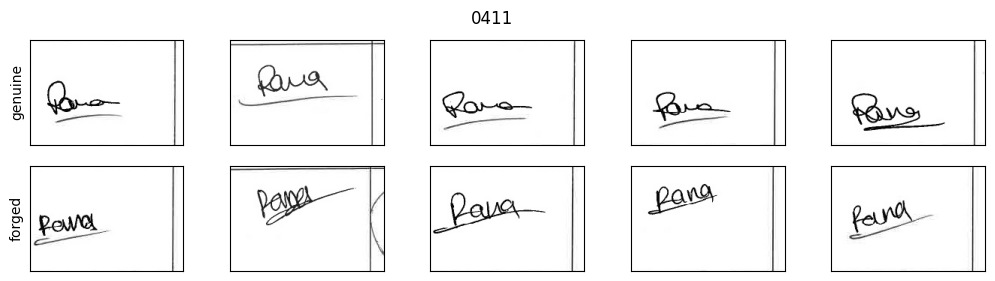

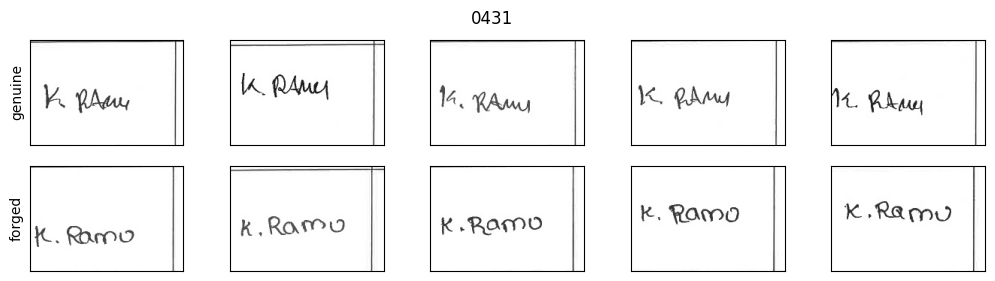

In [ ]:
from PIL import Image

def show_person(person_id, n=5):
    person = val_df[val_df.person_id == person_id]
    fig, axes = plt.subplots(2, n, figsize=(2.5 * n, 3))
    for row, label in enumerate(["genuine", "forged"]):
        paths = person[person.label == label].path.head(n)
        for ax, path in zip(axes[row], paths):
            ax.imshow(Image.open(DATA_ROOT / path).convert("L"), cmap="gray")
        axes[row][0].set_ylabel(label)
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(person_id)
    plt.show()

for person_id in val_df[val_df.source.str.startswith("b05")].person_id.unique()[:4]:
    show_person(person_id)